## 1. Setup
Read-only previews. Dataset images stay local; no splitting, annotation inference or export runs here.

In [1]:
from pathlib import Path
import sys
import torch
import cv2
import matplotlib.pyplot as plt

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/data_preparation").is_dir()
)
sys.path.insert(0, str(ROOT / "src"))
from data_preparation.visualization import (
    load_examples,
    plot_category,
    augmentation_cases,
    plot_augmentation,
)
from data_preparation.datasets import load_coco_splits

torch.set_num_threads(4)
cv2.setNumThreads(1)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
examples = load_examples(root=ROOT)
labelled = load_coco_splits(ROOT / "data/labelled" / examples["cutoff"])
rows_by_path = {row["path"].resolve(): row for row in labelled["train"]["rows"]}
samples = [
    rows_by_path[(ROOT / item["path"]).resolve()]
    for item in examples["augmentation_samples"]
]

## 2. Each augmentation: before and after
Three whole original training images; one transform at a time. No bbox crops or overlays. Fixed endpoints expose individual effects.

### Brightness

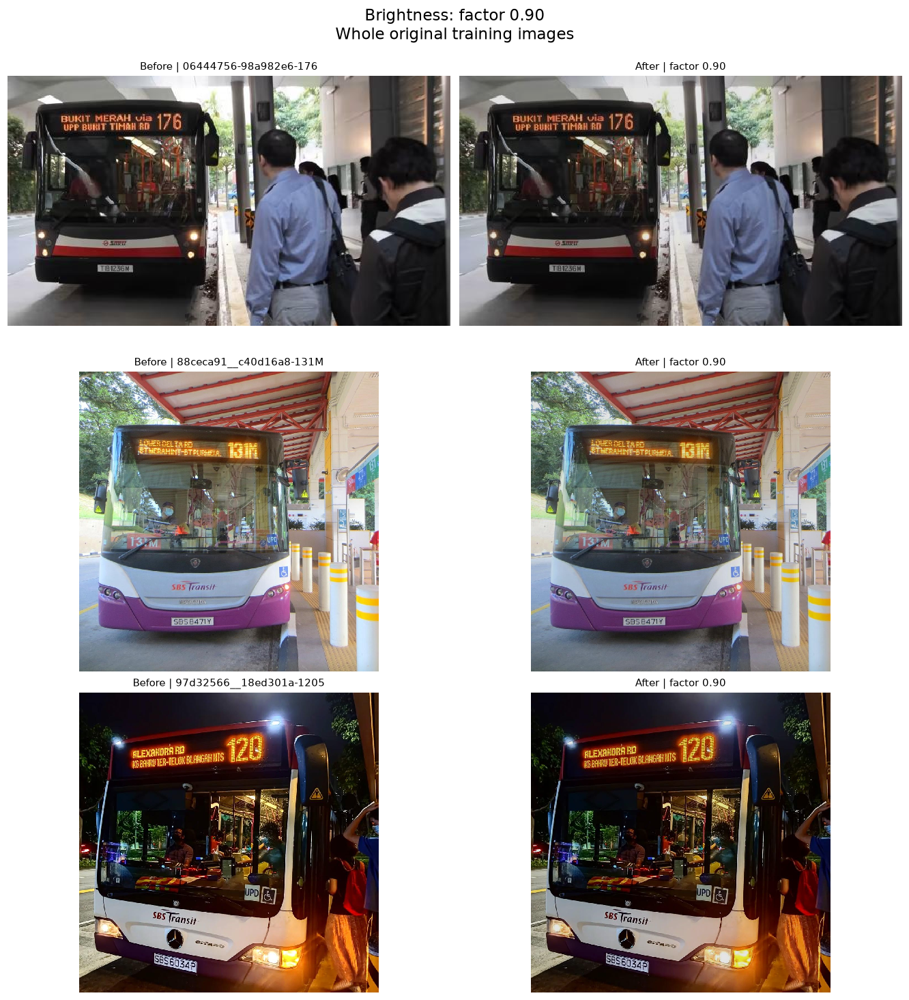

In [2]:
name, settings, parameters, description = augmentation_cases()[0]
figure = plot_augmentation(name, samples, settings, parameters, description)
plt.show()
plt.close(figure)

### Rotation

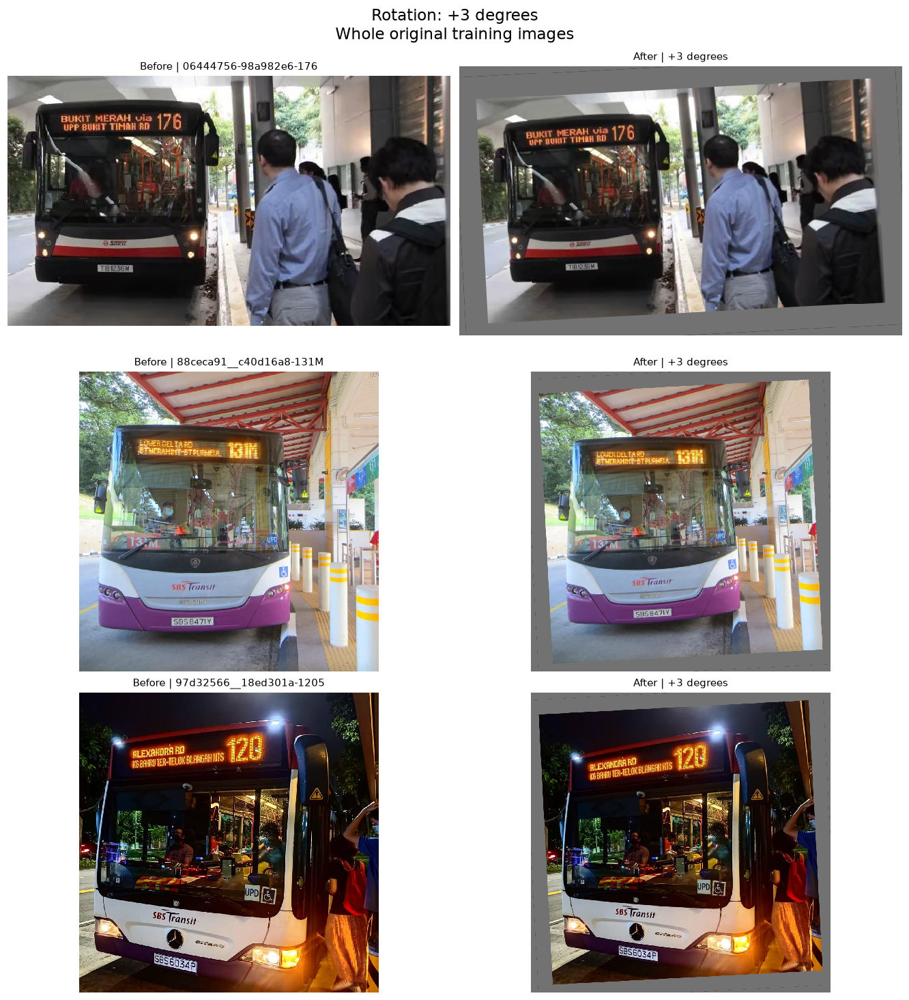

In [3]:
name, settings, parameters, description = augmentation_cases()[1]
figure = plot_augmentation(name, samples, settings, parameters, description)
plt.show()
plt.close(figure)

### Salt/pepper noise

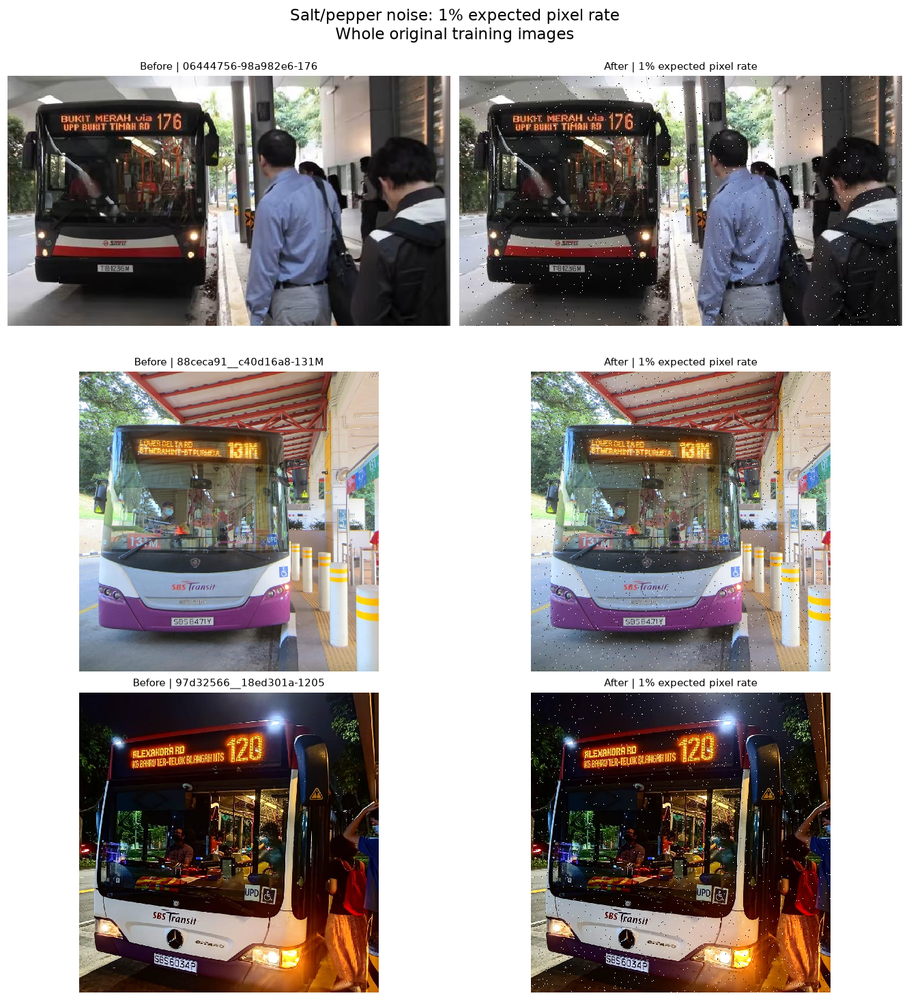

In [4]:
name, settings, parameters, description = augmentation_cases()[2]
figure = plot_augmentation(name, samples, settings, parameters, description)
plt.show()
plt.close(figure)

### Gaussian blur

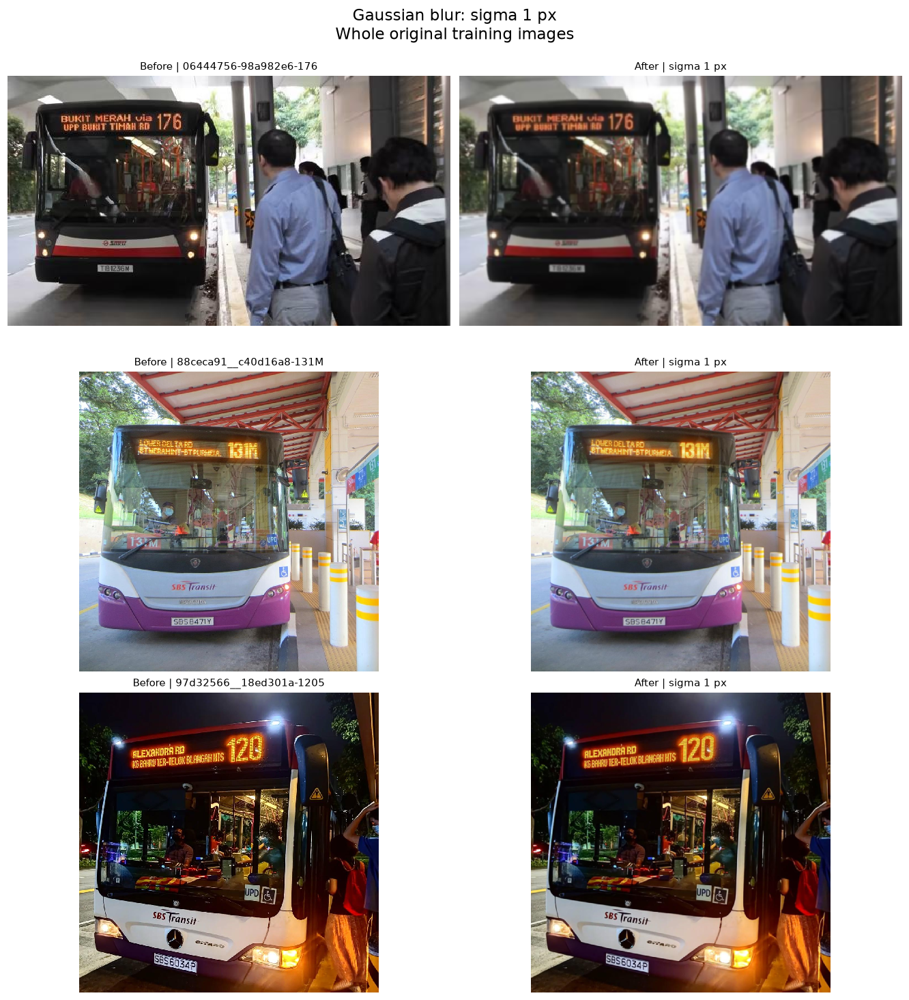

In [5]:
name, settings, parameters, description = augmentation_cases()[3]
figure = plot_augmentation(name, samples, settings, parameters, description)
plt.show()
plt.close(figure)

## 3. Image coverage categories
Three reviewed examples per category from [IMAGE_CATEGORIES.md](../data/IMAGE_CATEGORIES.md). These overlapping scene categories are separate from bounding-box classes.

### Viewing angle and display location

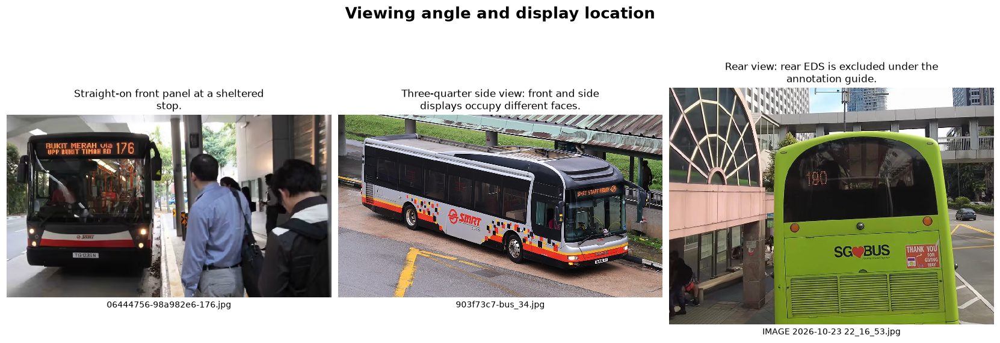

In [6]:
figure = plot_category(examples["categories"][0], root=ROOT)
plt.show()
plt.close(figure)

### Distance and image quality

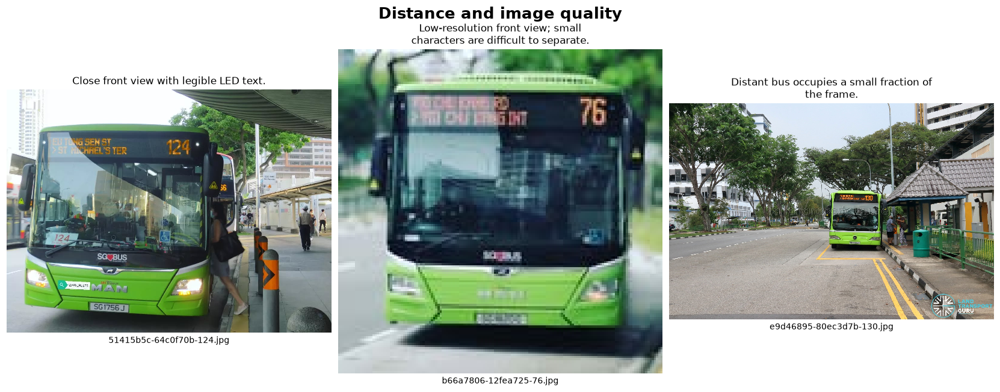

In [7]:
figure = plot_category(examples["categories"][1], root=ROOT)
plt.show()
plt.close(figure)

### Lighting and environment

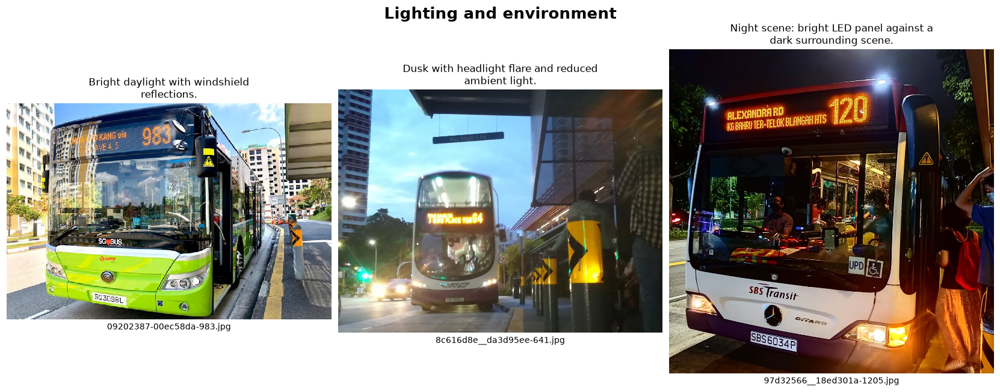

In [8]:
figure = plot_category(examples["categories"][2], root=ROOT)
plt.show()
plt.close(figure)

### EDS text and layout

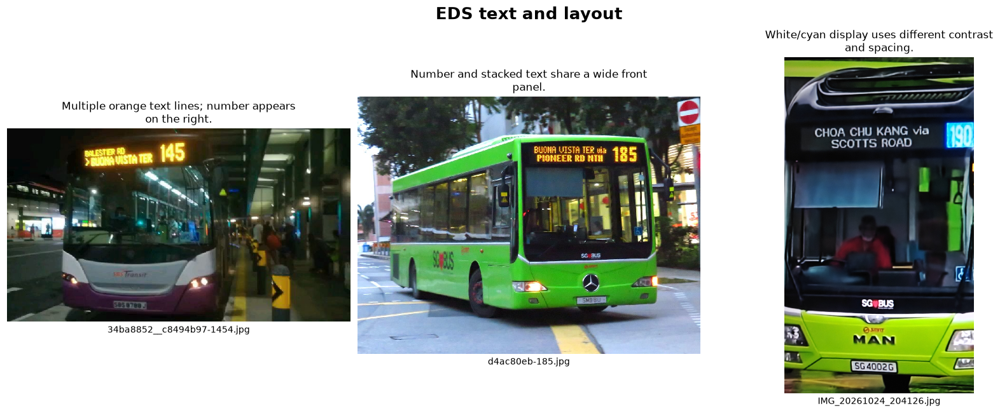

In [9]:
figure = plot_category(examples["categories"][3], root=ROOT)
plt.show()
plt.close(figure)

### Special display messages

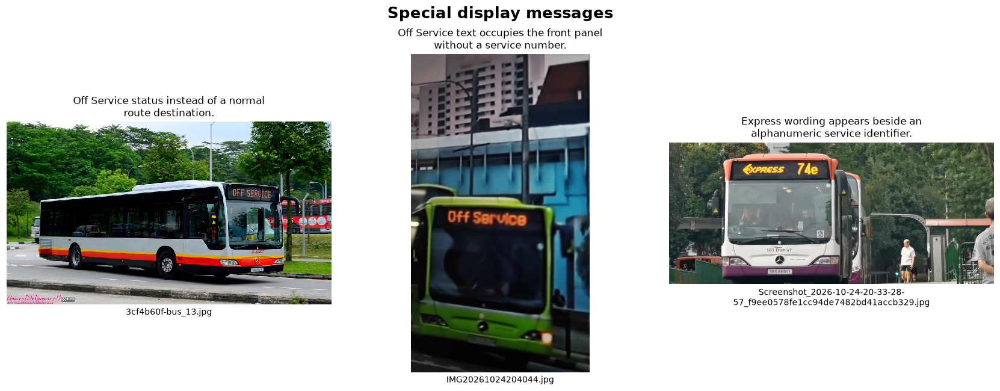

In [10]:
figure = plot_category(examples["categories"][4], root=ROOT)
plt.show()
plt.close(figure)

### Bus and operator variety

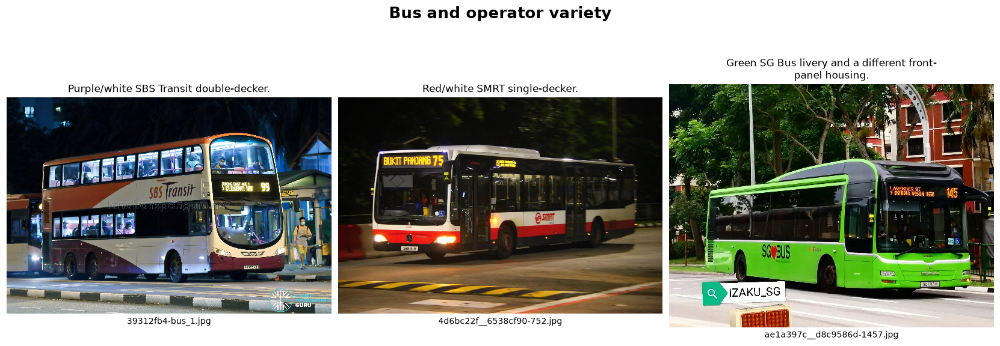

In [11]:
figure = plot_category(examples["categories"][5], root=ROOT)
plt.show()
plt.close(figure)

### Crowded or obstructed scenes

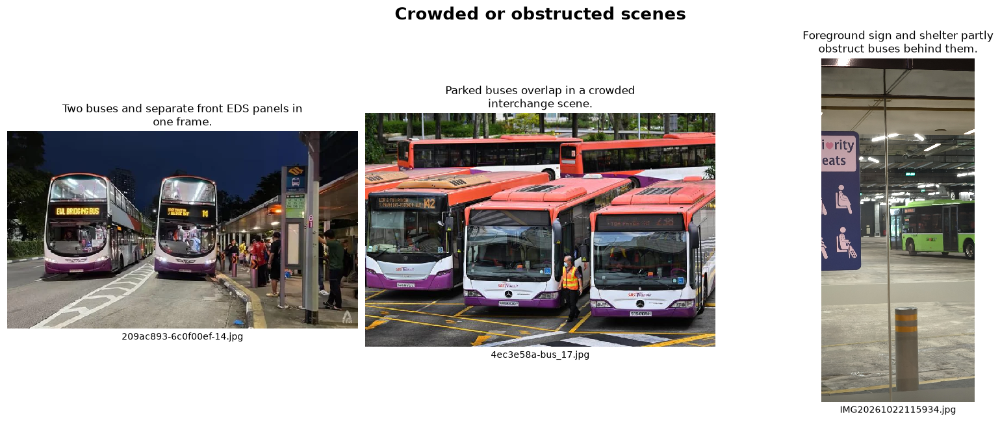

In [12]:
figure = plot_category(examples["categories"][6], root=ROOT)
plt.show()
plt.close(figure)

### Distracting text and hard negatives

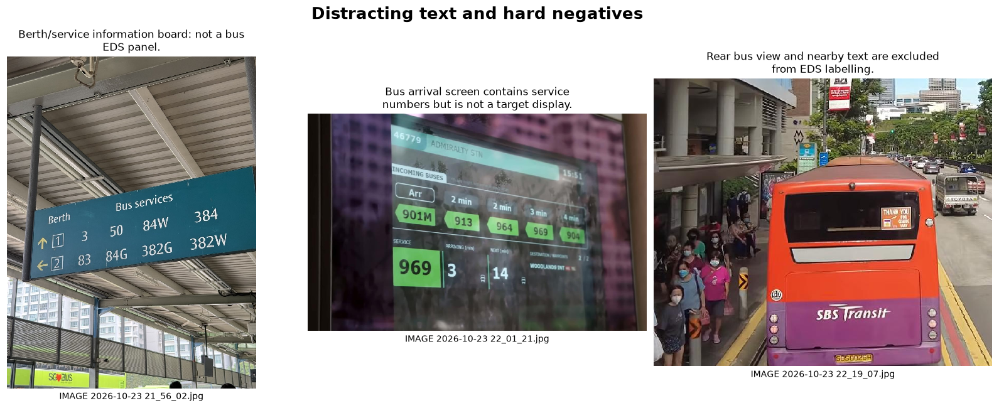

In [13]:
figure = plot_category(examples["categories"][7], root=ROOT)
plt.show()
plt.close(figure)